# Experiment 06 — Healthcare Records Automation using MCP
**Domain:** Healthcare (synthetic clinic data) &nbsp;|&nbsp; **Protocol:** Model Context Protocol (MCP) over stdio

> ⚠️ All patient data here is **synthetic**. Thresholds are simplified for a lab exercise — this is **not** a clinical decision tool.

### What this notebook builds
An AI-agent-style pipeline that talks to clinic "tools" through a real MCP client ↔ server connection:

```
User Request
   ↓
Planner Agent         (request → tasks + dependencies)
   ↓
MCP Client ── stdio ──► MCP Server  (6 healthcare tools)
   ↓
Supervisor Agent      (is every task valid for the tools the server really exposes?)
   ↓
Safety / Policy       (risk levels, PHI approval gate)
   ↓
Executor              (DAG: parallel layers + dependency gating + bounded retry)
   ↓
Validator             (software checks + clinical alerts)
   ↓
Trace / Logs / Report → Streamlit dashboard
```

### MCP tools
| Tool | Purpose | Risk | PHI |
|---|---|---|---|
| `list_records` | List clinic project files | LOW | – |
| `read_record_file` | Read a project file | LOW | – |
| `search_records` | Keyword search | LOW | – |
| `analyze_vitals` | Data-quality check + triage of all patients | MEDIUM | – |
| `patient_summary` | One patient's summary | **HIGH** | ✅ needs clinician approval |
| `run_validation_tests` | Run pytest on clinical rules (subprocess) | MEDIUM | – |

### Cell map
1 Install → 2 Workspace → 3 Clinic project → 4–9 Modules → 10+ Demonstrations → Report → **Streamlit app** → Download

## 1 · Install dependencies

In [1]:
!pip -q install "mcp>=1.10,<2" pytest pandas matplotlib "streamlit>=1.50"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.6/234.6 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 54.9 MB/s eta 0:00:00


## 2 · Workspace
Everything lives in one folder so it can be zipped and reused for Experiment 07.

In [2]:
import os, sys, json, asyncio, time
from pathlib import Path

BASE_DIR = Path("/content/Exp06_Healthcare_MCP")
(BASE_DIR / "clinic_project").mkdir(parents=True, exist_ok=True)
os.chdir(BASE_DIR)
sys.path.insert(0, str(BASE_DIR))

def show(title, obj):
    print("=" * 70); print(title); print("=" * 70)
    print(json.dumps(obj, indent=2, default=str) if not isinstance(obj, str) else obj)

print("Working folder:", BASE_DIR)

Working folder: /content/Exp06_Healthcare_MCP


## 3 · Synthetic clinic project
`vitals_rules.py` holds the clinical rules, `test_vitals_rules.py` tests them, `patients.csv` is generated with **deliberate special cases**
(missing values, impossible values, boundary values, critical patients) so every tool has something to find.

In [3]:
%%writefile clinic_project/vitals_rules.py
"""Vital-sign rules for the demo clinic.

EDUCATIONAL USE ONLY. Thresholds are simplified adult values for a lab
experiment. They are NOT a clinical decision tool and use synthetic data.
"""

VITAL_FIELDS = [
    "systolic_bp", "diastolic_bp", "heart_rate",
    "temperature_c", "spo2", "weight_kg", "height_cm",
]

# Physiologically plausible limits used for DATA QUALITY checks
VALID_RANGES = {
    "systolic_bp": (50, 260),
    "diastolic_bp": (30, 150),
    "heart_rate": (20, 250),
    "temperature_c": (30.0, 45.0),
    "spo2": (50, 100),
    "weight_kg": (1, 300),
    "height_cm": (30, 250),
}


def classify_bp(systolic, diastolic):
    if systolic >= 180 or diastolic >= 120:
        return "CRISIS"
    if systolic >= 140 or diastolic >= 90:
        return "HYPERTENSION_2"
    if systolic >= 130 or diastolic >= 80:
        return "HYPERTENSION_1"
    if systolic < 90 or diastolic < 60:
        return "LOW"
    if systolic >= 120:
        return "ELEVATED"
    return "NORMAL"


def classify_heart_rate(hr):
    if hr < 60:
        return "BRADYCARDIA"
    if hr > 100:
        return "TACHYCARDIA"
    return "NORMAL"


def classify_temperature(temp_c):
    if temp_c < 35.0:
        return "HYPOTHERMIA"
    if temp_c >= 39.0:
        return "HIGH_FEVER"
    if temp_c > 37.5:
        return "FEVER"
    return "NORMAL"


def classify_spo2(spo2):
    if spo2 < 90:
        return "CRITICAL"
    if spo2 < 95:
        return "LOW"
    return "NORMAL"


def calculate_bmi(weight_kg, height_cm):
    height_m = height_cm / 100.0
    return round(weight_kg / (height_m * height_m), 1)


def triage_level(c):
    """c = dict of classifications -> CRITICAL / URGENT / MONITOR / ROUTINE."""
    if c["bp"] == "CRISIS" or c["spo2"] == "CRITICAL" or c["temperature"] in ("HIGH_FEVER", "HYPOTHERMIA"):
        return "CRITICAL"
    if (c["bp"] in ("HYPERTENSION_2", "LOW") or c["heart_rate"] == "TACHYCARDIA"
            or c["spo2"] == "LOW" or c["temperature"] == "FEVER"):
        return "URGENT"
    if c["bp"] in ("HYPERTENSION_1", "ELEVATED") or c["heart_rate"] == "BRADYCARDIA":
        return "MONITOR"
    return "ROUTINE"


def parse_vitals(row):
    """Return (values, problems). Empty/non-numeric/out-of-range -> problems."""
    values, problems = {}, []
    for field in VITAL_FIELDS:
        raw = str(row.get(field, "")).strip()
        if raw == "":
            problems.append(f"Missing value: {field}")
            continue
        try:
            number = float(raw)
        except ValueError:
            problems.append(f"Non-numeric value: {field}={raw}")
            continue
        low, high = VALID_RANGES[field]
        if not low <= number <= high:
            problems.append(f"Out of range: {field}={number} (allowed {low}-{high})")
            continue
        values[field] = number
    return values, problems


def assess_patient(row):
    """Full assessment of one patient row. Never raises on bad data."""
    pid = str(row.get("patient_id", "")).strip() or "UNKNOWN"
    values, problems = parse_vitals(row)
    if problems:
        return {"patient_id": pid, "valid": False, "problems": problems}

    classes = {
        "bp": classify_bp(values["systolic_bp"], values["diastolic_bp"]),
        "heart_rate": classify_heart_rate(values["heart_rate"]),
        "temperature": classify_temperature(values["temperature_c"]),
        "spo2": classify_spo2(values["spo2"]),
    }
    findings = [f"{k}: {v}" for k, v in classes.items() if v not in ("NORMAL",)]
    return {
        "patient_id": pid,
        "valid": True,
        "classifications": classes,
        "bmi": calculate_bmi(values["weight_kg"], values["height_cm"]),
        "triage": triage_level(classes),
        "findings": findings,
    }

Writing clinic_project/vitals_rules.py


In [4]:
%%writefile clinic_project/test_vitals_rules.py
import pytest
from vitals_rules import (
    classify_bp, classify_heart_rate, classify_temperature, classify_spo2,
    calculate_bmi, assess_patient, parse_vitals,
)


@pytest.mark.parametrize("sys_bp,dia_bp,expected", [
    (110, 70, "NORMAL"),
    (125, 75, "ELEVATED"),
    (130, 75, "HYPERTENSION_1"),
    (140, 85, "HYPERTENSION_2"),
    (180, 100, "CRISIS"),
    (85, 55, "LOW"),
])
def test_bp(sys_bp, dia_bp, expected):
    assert classify_bp(sys_bp, dia_bp) == expected


@pytest.mark.parametrize("hr,expected", [
    (59, "BRADYCARDIA"), (60, "NORMAL"), (100, "NORMAL"), (101, "TACHYCARDIA"),
])
def test_heart_rate_boundaries(hr, expected):
    assert classify_heart_rate(hr) == expected


@pytest.mark.parametrize("temp,expected", [
    (34.9, "HYPOTHERMIA"), (36.8, "NORMAL"), (37.5, "NORMAL"),
    (37.6, "FEVER"), (39.0, "HIGH_FEVER"),
])
def test_temperature(temp, expected):
    assert classify_temperature(temp) == expected


@pytest.mark.parametrize("spo2,expected", [
    (89, "CRITICAL"), (90, "LOW"), (94, "LOW"), (95, "NORMAL"),
])
def test_spo2_boundaries(spo2, expected):
    assert classify_spo2(spo2) == expected


def test_bmi():
    assert calculate_bmi(70, 175) == 22.9


def _row(**overrides):
    base = dict(patient_id="T001", systolic_bp="115", diastolic_bp="75",
                heart_rate="72", temperature_c="36.8", spo2="98",
                weight_kg="70", height_cm="175")
    base.update({k: str(v) for k, v in overrides.items()})
    return base


def test_routine_patient():
    result = assess_patient(_row())
    assert result["valid"] and result["triage"] == "ROUTINE"


def test_critical_patient():
    assert assess_patient(_row(spo2=88))["triage"] == "CRITICAL"


def test_missing_value_is_invalid_not_crash():
    result = assess_patient(_row(heart_rate=""))
    assert not result["valid"] and "Missing value" in result["problems"][0]


def test_out_of_range_rejected():
    _, problems = parse_vitals(_row(spo2=140))
    assert any("Out of range" in p for p in problems)


def test_non_numeric_rejected():
    _, problems = parse_vitals(_row(temperature_c="hot"))
    assert any("Non-numeric" in p for p in problems)

Writing clinic_project/test_vitals_rules.py


In [5]:
%%writefile create_sample_project.py
"""Creates the SYNTHETIC clinic project used by Experiment 06 (no real patient data)."""
import csv
import random
from pathlib import Path

FIRST = ["Aarav", "Diya", "Kabir", "Ira", "Neel", "Anaya", "Rohan", "Meera", "Vihaan", "Sara",
         "Arjun", "Tara", "Ishaan", "Kiara", "Dev", "Riya", "Yash", "Naina", "Karan", "Pooja"]
LAST = ["Shah", "Mehta", "Patil", "Desai", "Joshi", "Nair", "Rao", "Iyer", "Kulkarni", "Gupta"]
COMPLAINTS = ["routine checkup", "cough", "fever", "headache", "back pain",
              "fatigue", "chest pain", "shortness of breath"]

# Deliberate special cases so every tool has something interesting to find
SPECIAL = {
    "P004": dict(temperature_c=39.4, heart_rate=112, chief_complaint="fever"),
    "P007": dict(heart_rate=""),                                   # missing value
    "P008": dict(heart_rate=48),                                   # bradycardia
    "P013": dict(spo2=140),                                        # impossible value
    "P016": dict(systolic_bp=135, diastolic_bp=85),                # hypertension stage 1
    "P019": dict(spo2=88, chief_complaint="shortness of breath"),  # critical SpO2
    "P021": dict(systolic_bp=192, diastolic_bp=124, chief_complaint="headache"),  # crisis
    "P022": dict(systolic_bp=150, diastolic_bp=95),                # hypertension stage 2
    "P024": dict(systolic_bp=128, diastolic_bp=78),                # elevated
    "P026": dict(heart_rate=100),                                  # boundary: normal
    "P027": dict(heart_rate=101),                                  # boundary: tachycardia
    "P028": dict(spo2=95),                                         # boundary: normal
    "P029": dict(spo2=94),                                         # boundary: low
    "P030": dict(temperature_c=-5),                                # impossible value
}

COLUMNS = ["patient_id", "patient_name", "age", "sex", "systolic_bp", "diastolic_bp",
           "heart_rate", "temperature_c", "spo2", "weight_kg", "height_cm", "chief_complaint"]


def create_sample_project(project_dir, n_patients=30, seed=42):
    project_dir = Path(project_dir)
    project_dir.mkdir(parents=True, exist_ok=True)
    rng = random.Random(seed)

    rows = []
    for i in range(1, n_patients + 1):
        pid = f"P{i:03d}"
        row = {
            "patient_id": pid,
            "patient_name": f"{rng.choice(FIRST)} {rng.choice(LAST)}",
            "age": rng.randint(18, 80),
            "sex": rng.choice(["F", "M"]),
            "systolic_bp": rng.randint(105, 119),
            "diastolic_bp": rng.randint(65, 78),
            "heart_rate": rng.randint(62, 98),
            "temperature_c": round(rng.uniform(36.2, 37.2), 1),
            "spo2": rng.randint(96, 99),
            "weight_kg": rng.randint(50, 95),
            "height_cm": rng.randint(150, 185),
            "chief_complaint": rng.choice(COMPLAINTS[:6]),
        }
        row.update(SPECIAL.get(pid, {}))
        rows.append(row)

    with open(project_dir / "patients.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=COLUMNS)
        writer.writeheader()
        writer.writerows(rows)

    (project_dir / "README.md").write_text(
        "# Demo Clinic Project\n\n"
        "SYNTHETIC data for MCP healthcare automation experiments.\n"
        "No real patient information. Not for clinical use.\n\n"
        "Files:\n- patients.csv\n- vitals_rules.py\n- test_vitals_rules.py\n",
        encoding="utf-8",
    )
    return len(rows)


if __name__ == "__main__":
    import sys
    target = sys.argv[1] if len(sys.argv) > 1 else "clinic_project"
    print("Patients created:", create_sample_project(target))

Writing create_sample_project.py


In [6]:
from create_sample_project import create_sample_project
import pandas as pd

n = create_sample_project(BASE_DIR / "clinic_project")
print("Synthetic patients created:", n)
pd.read_csv(BASE_DIR / "clinic_project" / "patients.csv").head(10)

Synthetic patients created: 30


,patient_id,patient_name,age,sex,systolic_bp,diastolic_bp,heart_rate,temperature_c,spo2,weight_kg,height_cm,chief_complaint
0,P001,Ira Shah,65,M,108,68,70.0,36.9,96,87,177,routine checkup
1,P002,Aarav Mehta,31,F,113,74,63.0,36.8,99,64,178,back pain
2,P003,Vihaan Shah,66,F,116,71,83.0,36.5,97,71,156,routine checkup
3,P004,Ishaan Mehta,40,M,114,69,112.0,39.4,96,74,155,fever
4,P005,Sara Gupta,74,M,114,68,66.0,36.2,97,68,155,cough
5,P006,Ira Rao,35,M,115,78,85.0,36.4,98,63,167,fatigue
6,P007,Kabir Gupta,58,F,113,76,NaN,36.4,99,67,185,cough
7,P008,Arjun Shah,32,F,117,70,48.0,36.5,97,86,170,cough
8,P009,Riya Rao,74,M,107,69,70.0,36.4,98,87,177,back pain
9,P010,Ishaan Nair,32,F,113,72,67.0,37.0,96,59,160,fatigue


In [7]:
!cd clinic_project && python -m pytest -q -p no:cacheprovider

.........................                                                [100%]
25 passed in 0.04s


## 4 · MCP Server
Built with **FastMCP**. Notes on the design:
- Every tool is `async` and decorated with `@mcp.tool()`; the **docstring becomes the tool description** that clients discover.
- `@safe_tool` converts exceptions into structured error results (`security`, `input`, `execution_error`) instead of crashing.
- `safe_path()` blocks path traversal (`../../etc/passwd`) and non-allowed file types.
- stdout is the protocol channel, so the server **logs to a file only** — never `print()`.
- Logs contain tool names and timings, **never patient data**.

In [8]:
%%writefile mcp_server.py
"""Healthcare Records Automation MCP Server (stdio transport).

IMPORTANT: with stdio transport, stdout is the protocol channel.
Never print() here - log to a file instead.
"""
import asyncio
import csv
import functools
import logging
import os
import re
import sys
import time
from collections import Counter
from pathlib import Path

from mcp.server.fastmcp import FastMCP

BASE_DIR = Path(__file__).resolve().parent
PROJECT_DIR = Path(os.environ.get("CLINIC_PROJECT_DIR", BASE_DIR / "clinic_project")).resolve()
LOG_DIR = BASE_DIR / "logs"
LOG_DIR.mkdir(exist_ok=True)

logging.basicConfig(
    filename=LOG_DIR / "server.log",
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)
log = logging.getLogger("healthcare-mcp-server")

sys.path.insert(0, str(PROJECT_DIR))
import vitals_rules  # noqa: E402  (lives inside the clinic project)

mcp = FastMCP("Healthcare Records Automation Server")

ALLOWED_EXTENSIONS = {".csv", ".py", ".md", ".txt"}
PATIENT_ID_PATTERN = re.compile(r"^P\d{3}$")


# --------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------
class SecurityError(Exception):
    pass


class InputError(Exception):
    pass


def safe_path(relative_path: str) -> Path:
    """Resolve a path and make sure it stays inside the clinic project."""
    path = (PROJECT_DIR / relative_path).resolve()
    if not path.is_relative_to(PROJECT_DIR):
        raise SecurityError("Path outside clinic project directory is not allowed.")
    if path.suffix.lower() not in ALLOWED_EXTENSIONS:
        raise SecurityError(f"File type '{path.suffix}' is not allowed.")
    return path


def ok(**payload):
    return {"status": "success", **payload}


def fail(error_type, message):
    return {"status": "error", "error_type": error_type, "message": message}


def safe_tool(func):
    """Convert exceptions into structured error results + audit logging."""
    @functools.wraps(func)
    async def wrapper(*args, **kwargs):
        started = time.perf_counter()
        try:
            result = await func(*args, **kwargs)
        except SecurityError as e:
            result = fail("security", str(e))
        except InputError as e:
            result = fail("input", str(e))
        except FileNotFoundError as e:
            result = fail("input", f"File not found: {e.filename}")
        except Exception as e:  # noqa: BLE001
            log.exception("Unexpected failure in %s", func.__name__)
            result = fail("execution_error", f"{type(e).__name__}: {e}")
        elapsed = round((time.perf_counter() - started) * 1000, 2)
        # Log tool name + outcome only - never patient data
        log.info("tool=%s status=%s time_ms=%s", func.__name__, result["status"], elapsed)
        return result
    return wrapper


def load_patients(file_path="patients.csv"):
    path = safe_path(file_path)
    with open(path, newline="", encoding="utf-8") as f:
        rows = [{k: (v or "").strip() for k, v in r.items()} for r in csv.DictReader(f)]
    if rows and "patient_id" not in rows[0]:
        raise InputError("CSV has no 'patient_id' column.")
    return rows


# --------------------------------------------------------------------------
# MCP tools
# --------------------------------------------------------------------------
@mcp.tool()
@safe_tool
async def list_records() -> dict:
    """List the files available in the clinic project (name, type, size)."""
    files = [
        {"name": p.name, "type": p.suffix.lstrip("."), "size_bytes": p.stat().st_size}
        for p in sorted(PROJECT_DIR.iterdir())
        if p.is_file() and p.suffix.lower() in ALLOWED_EXTENSIONS
    ]
    return ok(files=files, count=len(files))


@mcp.tool()
@safe_tool
async def read_record_file(file_path: str, max_chars: int = 4000) -> dict:
    """Read a text/CSV/Python file from the clinic project (truncated to max_chars)."""
    path = safe_path(file_path)
    if not path.is_file():
        raise InputError(f"'{file_path}' is not a file.")
    max_chars = max(100, min(int(max_chars), 20000))
    text = path.read_text(encoding="utf-8")
    return ok(file=file_path, content=text[:max_chars],
              truncated=len(text) > max_chars, total_chars=len(text))


@mcp.tool()
@safe_tool
async def search_records(keyword: str) -> dict:
    """Case-insensitive keyword search across clinic project files (max 50 matches)."""
    keyword = keyword.strip()
    if len(keyword) < 2:
        raise InputError("Keyword must be at least 2 characters.")
    matches, limit = [], 50
    for path in sorted(PROJECT_DIR.iterdir()):
        if not path.is_file() or path.suffix.lower() not in ALLOWED_EXTENSIONS:
            continue
        for number, line in enumerate(path.read_text(encoding="utf-8").splitlines(), start=1):
            if keyword.lower() in line.lower():
                matches.append({"file": path.name, "line": number, "content": line.strip()[:160]})
    return ok(keyword=keyword, match_count=len(matches),
              matches=matches[:limit], truncated=len(matches) > limit)


@mcp.tool()
@safe_tool
async def analyze_vitals(file_path: str = "patients.csv") -> dict:
    """Screen every patient row: validate data quality and assign a triage level."""
    rows = load_patients(file_path)
    assessments = [vitals_rules.assess_patient(r) for r in rows]
    valid = [a for a in assessments if a["valid"]]
    invalid = [a for a in assessments if not a["valid"]]
    triage_counts = Counter(a["triage"] for a in valid)
    return ok(
        file=file_path,
        total_records=len(rows),
        valid_count=len(valid),
        invalid_count=len(invalid),
        triage_counts={k: triage_counts.get(k, 0) for k in ("CRITICAL", "URGENT", "MONITOR", "ROUTINE")},
        critical_patients=[a["patient_id"] for a in valid if a["triage"] == "CRITICAL"],
        invalid_records=[{"patient_id": a["patient_id"], "problems": a["problems"]} for a in invalid],
        patients=[{"patient_id": a["patient_id"], "triage": a["triage"], "bmi": a["bmi"],
                   "findings": a["findings"]} for a in valid],
    )


@mcp.tool()
@safe_tool
async def patient_summary(patient_id: str) -> dict:
    """Return a clinical summary for ONE patient id (e.g. P021). Handles PHI - needs approval."""
    patient_id = patient_id.strip().upper()
    if not PATIENT_ID_PATTERN.match(patient_id):
        raise InputError("patient_id must look like P001.")
    for row in load_patients():
        if row["patient_id"] == patient_id:
            assessment = vitals_rules.assess_patient(row)
            return ok(patient_id=patient_id, age=row.get("age"), sex=row.get("sex"),
                      chief_complaint=row.get("chief_complaint"), assessment=assessment)
    raise InputError(f"Patient '{patient_id}' not found.")


@mcp.tool()
@safe_tool
async def run_validation_tests(timeout_seconds: int = 30) -> dict:
    """Run the clinic project's pytest suite (starts a subprocess - MEDIUM risk)."""
    timeout_seconds = max(5, min(int(timeout_seconds), 120))
    started = time.perf_counter()
    proc = await asyncio.create_subprocess_exec(
        sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider",
        cwd=str(PROJECT_DIR),
        stdout=asyncio.subprocess.PIPE, stderr=asyncio.subprocess.PIPE,
        env={**os.environ, "PYTHONDONTWRITEBYTECODE": "1"},
    )
    try:
        out, err = await asyncio.wait_for(proc.communicate(), timeout=timeout_seconds)
    except asyncio.TimeoutError:
        proc.kill()
        return fail("timeout", f"Tests exceeded {timeout_seconds} seconds.")
    text = out.decode(errors="replace")
    passed = re.search(r"(\d+) passed", text)
    failed = re.search(r"(\d+) failed", text)
    return ok(
        return_code=proc.returncode,
        passed=int(passed.group(1)) if passed else 0,
        failed=int(failed.group(1)) if failed else 0,
        all_passed=proc.returncode == 0,
        duration_ms=round((time.perf_counter() - started) * 1000, 1),
        output_tail="\n".join(text.strip().splitlines()[-5:]),
        stderr_tail=err.decode(errors="replace")[-300:],
    )


if __name__ == "__main__":
    mcp.run(transport="stdio")

Writing mcp_server.py


## 5 · MCP Client
One **persistent** `ClientSession` for a whole workflow (connect once, call many times). Results are normalised to
`{tool, status, error_type, message, data, execution_time_ms}` so the rest of the system never touches raw MCP objects.

In [9]:
%%writefile mcp_client.py
"""MCP client: ONE persistent stdio session, normalised results."""
import asyncio
import json
import os
import sys
import time
from contextlib import AsyncExitStack
from pathlib import Path

from mcp import ClientSession
from mcp.client.stdio import StdioServerParameters, stdio_client

BASE_DIR = Path(__file__).resolve().parent
LOG_DIR = BASE_DIR / "logs"
LOG_DIR.mkdir(exist_ok=True)


class MCPClient:
    """Async context manager:  async with MCPClient() as client: ..."""

    def __init__(self, server_script=None, project_dir=None, call_timeout=60):
        self.server_script = str(server_script or BASE_DIR / "mcp_server.py")
        self.project_dir = str(project_dir or BASE_DIR / "clinic_project")
        self.call_timeout = call_timeout
        self.session = None
        self.connect_ms = None
        self._stack = None
        self._errlog = None

    async def __aenter__(self):
        started = time.perf_counter()
        self._stack = AsyncExitStack()
        self._errlog = open(LOG_DIR / "server_stderr.log", "a")
        params = StdioServerParameters(
            command=sys.executable,
            args=[self.server_script],
            env={**os.environ, "CLINIC_PROJECT_DIR": self.project_dir},
        )
        read, write = await self._stack.enter_async_context(stdio_client(params, errlog=self._errlog))
        self.session = await self._stack.enter_async_context(ClientSession(read, write))
        await self.session.initialize()
        self.connect_ms = round((time.perf_counter() - started) * 1000, 1)
        return self

    async def __aexit__(self, *exc):
        try:
            await self._stack.aclose()
        finally:
            self._errlog.close()

    # ---------------------------------------------------------------- discovery
    async def list_tools(self):
        result = await self.session.list_tools()
        return [{"name": t.name, "description": (t.description or "").strip(),
                 "input_schema": t.inputSchema} for t in result.tools]

    # ---------------------------------------------------------------- tool call
    async def call(self, tool, arguments=None):
        """Call a tool and return a normalised dict (never raises)."""
        started = time.perf_counter()
        base = {"tool": tool, "arguments": arguments or {}}
        try:
            raw = await asyncio.wait_for(
                self.session.call_tool(tool, arguments=arguments or {}),
                timeout=self.call_timeout,
            )
        except asyncio.TimeoutError:
            return {**base, "status": "error", "error_type": "timeout",
                    "message": f"No response within {self.call_timeout}s.",
                    "data": {}, "execution_time_ms": self._ms(started)}
        except Exception as e:  # noqa: BLE001 - transport / protocol failure
            return {**base, "status": "error", "error_type": "execution_error",
                    "message": f"{type(e).__name__}: {e}",
                    "data": {}, "execution_time_ms": self._ms(started)}
        return {**base, **self._normalise(raw), "execution_time_ms": self._ms(started)}

    @staticmethod
    def _ms(started):
        return round((time.perf_counter() - started) * 1000, 2)

    @staticmethod
    def _normalise(raw):
        text = "\n".join(c.text for c in raw.content if hasattr(c, "text"))
        if raw.isError:  # protocol-level error (bad arguments, unknown tool, ...)
            return {"status": "error", "error_type": "tool_error", "message": text, "data": {}}
        try:
            payload = json.loads(text)
        except json.JSONDecodeError:
            payload = getattr(raw, "structuredContent", None) or {"text": text}
        if not isinstance(payload, dict):
            payload = {"result": payload}
        status = payload.pop("status", "success")
        if status == "error":
            return {"status": "error", "error_type": payload.get("error_type", "tool_error"),
                    "message": payload.get("message", ""), "data": {}}
        return {"status": "success", "error_type": None, "message": "", "data": payload}

Writing mcp_client.py


## 6 · Safety / policy layer, failure classification and retry

In [10]:
%%writefile policy.py
"""Safety / policy layer + failure classification + retry recovery."""
import asyncio

# risk: LOW / MEDIUM / HIGH.  phi=True -> touches individual patient data.
TOOL_POLICIES = {
    "list_records":         {"risk": "LOW",    "phi": False, "approval_required": False},
    "read_record_file":     {"risk": "LOW",    "phi": False, "approval_required": False},
    "search_records":       {"risk": "LOW",    "phi": False, "approval_required": False},
    "analyze_vitals":       {"risk": "MEDIUM", "phi": False, "approval_required": False},
    "patient_summary":      {"risk": "HIGH",   "phi": True,  "approval_required": True},
    "run_validation_tests": {"risk": "MEDIUM", "phi": False, "approval_required": False},
}


def validate_tool_policy(tool_name, approvals=()):
    """approvals = set of tool names a clinician has explicitly approved."""
    policy = TOOL_POLICIES.get(tool_name)
    if policy is None:
        return {"allowed": False, "risk": "UNKNOWN", "phi": False,
                "reason": "No security policy defined for this tool."}
    if policy["approval_required"] and tool_name not in set(approvals):
        return {"allowed": False, "risk": policy["risk"], "phi": policy["phi"],
                "reason": "Clinician approval required for patient-level (PHI) access."}
    return {"allowed": True, "risk": policy["risk"], "phi": policy["phi"],
            "reason": "Allowed by policy."}


# ---------------------------------------------------------------- failures
def classify_failure(result):
    """Map a normalised client result to a failure category (Table 4)."""
    if result.get("status") == "success":
        return {"failure_type": "none", "retryable": False, "reason": "Execution successful."}

    kind = (result.get("error_type") or "").lower()
    message = (result.get("message") or "").lower()

    if kind == "security":
        return {"failure_type": "security_error", "retryable": False,
                "reason": "Blocked by path / file-type security rules."}
    if kind == "input" or any(k in message for k in ("validation error", "unknown tool", "not found", "required")):
        return {"failure_type": "input_error", "retryable": False,
                "reason": "Invalid input or missing resource - retrying cannot help."}
    if kind == "timeout":
        return {"failure_type": "timeout", "retryable": True, "reason": "Operation timed out."}
    if kind == "execution_error":
        return {"failure_type": "execution_error", "retryable": True,
                "reason": "Unexpected execution failure - possibly transient."}
    return {"failure_type": "tool_error", "retryable": False, "reason": "Tool returned an error result."}


async def execute_with_recovery(call_fn, max_retries=2, retry_delay=0.3):
    """call_fn: async callable returning a normalised result. Bounded retry."""
    history, attempts, result = [], 0, None
    while attempts <= max_retries:
        attempts += 1
        result = await call_fn()
        info = classify_failure(result)
        history.append({"attempt": attempts, "status": result["status"],
                        "failure_type": info["failure_type"], "retryable": info["retryable"]})
        if result["status"] == "success":
            return {"status": "success", "attempts": attempts, "recovery_action": "completed",
                    "history": history, "result": result}
        if not info["retryable"]:
            return {"status": "failed", "attempts": attempts, "recovery_action": "stopped_no_retry",
                    "history": history, "result": result}
        if attempts <= max_retries:
            await asyncio.sleep(retry_delay)
    return {"status": "failed", "attempts": attempts, "recovery_action": "retry_limit_reached",
            "history": history, "result": result}

Writing policy.py


## 7 · Planner Agent and Supervisor Agent

In [11]:
%%writefile planner.py
"""Planner agent (request -> tasks) and Supervisor agent (plan -> approved plan)."""
import re

FILE_RE = re.compile(r"\b([\w\-]+\.(?:csv|py|md|txt))\b", re.I)
PATIENT_RE = re.compile(r"\bP\d{3}\b", re.I)
KEYWORD_STOP = {"records", "record", "patients", "patient", "all", "the", "for", "in", "and", "then", "files"}


def _extract_keyword(text):
    quoted = re.search(r"[\"']([^\"']{2,40})[\"']", text)
    if quoted:
        return quoted.group(1).strip()
    for word in re.findall(r"(?:search|find|look up)(?:\s+for)?\s+((?:\w+\s+){0,3}?\w+)", text):
        for token in word.split():
            if token not in KEYWORD_STOP:
                return token
    return None


def planner_agent(user_request):
    """Rule-based planner. Returns a list of tasks with explicit dependencies."""
    text = user_request.lower()
    files = FILE_RE.findall(user_request)
    patient_ids = [p.upper() for p in PATIENT_RE.findall(user_request)]
    tasks = []

    def add(tool, arguments, reason, depends_on=()):
        task_id = f"TASK-{len(tasks) + 1:03d}"
        tasks.append({"task_id": task_id, "step": len(tasks) + 1, "tool": tool,
                      "arguments": arguments, "depends_on": list(depends_on), "reason": reason})
        return task_id

    if re.search(r"\blist\b|\bwhat files\b|\bavailable (files|records)\b", text):
        add("list_records", {}, "User asked what is available.")

    if re.search(r"\b(read|open|show|display)\b", text) and files:
        add("read_record_file", {"file_path": files[0]}, f"User asked to read {files[0]}.")

    if re.search(r"\b(search|find|look up)\b", text):
        keyword = _extract_keyword(user_request)
        if keyword:
            add("search_records", {"keyword": keyword}, f"Keyword search for '{keyword}'.")

    analysis_id = None
    if re.search(r"analy[sz]|vitals?|triage|screen", text):
        csv_files = [f for f in files if f.lower().endswith(".csv")]
        analysis_id = add("analyze_vitals", {"file_path": csv_files[0]} if csv_files else {},
                          "Screen patient vitals and assign triage levels.")

    if patient_ids and re.search(r"summar|patient|details|record", text):
        add("patient_summary", {"patient_id": patient_ids[0]},
            f"Patient-level summary for {patient_ids[0]} (PHI).")

    if re.search(r"\btests?\b|validation rules|unit test", text):
        add("run_validation_tests", {}, "Verify the clinical rules still pass their tests.",
            depends_on=[analysis_id] if analysis_id else [])

    return tasks


def supervisor_agent(plan, tool_schemas):
    """Validate a plan against the tools the MCP server really exposes.

    tool_schemas: {tool_name: input_schema_dict} from tool discovery.
    """
    approved, rejected = [], []
    approved_ids = set()

    def reject(task, reason):
        rejected.append({"task_id": task.get("task_id"), "tool": task.get("tool"), "reason": reason})

    for task in plan:
        tool, args = task.get("tool"), task.get("arguments", {})
        if tool not in tool_schemas:
            reject(task, "Tool is not available on the MCP server.")
            continue
        if not isinstance(args, dict):
            reject(task, "Arguments must be a dictionary.")
            continue
        schema = tool_schemas[tool]
        missing = [r for r in schema.get("required", []) if r not in args]
        unknown = [a for a in args if a not in schema.get("properties", {})]
        if missing:
            reject(task, f"Missing required argument(s): {', '.join(missing)}.")
            continue
        if unknown:
            reject(task, f"Unknown argument(s): {', '.join(unknown)}.")
            continue
        bad_deps = [d for d in task.get("depends_on", []) if d not in approved_ids]
        if bad_deps:
            reject(task, f"Depends on task(s) that were not approved: {', '.join(bad_deps)}.")
            continue
        approved.append(task)
        approved_ids.add(task["task_id"])

    return {"approved": approved, "rejected": rejected}

Writing planner.py


## 8 · Validator Agent

In [12]:
%%writefile validator.py
"""Validator agent: checks that results are acceptable AND internally consistent."""


def _check(tool, data):
    """Return (valid, reason) from the tool-specific payload."""
    if tool == "list_records":
        names = [f["name"] for f in data.get("files", [])]
        return ("patients.csv" in names, "patients.csv present in file listing." if "patients.csv" in names
                else "patients.csv missing from listing.")
    if tool == "read_record_file":
        return (bool(data.get("content")), "File content returned." if data.get("content") else "Empty content.")
    if tool == "search_records":
        return ("matches" in data and data.get("match_count", -1) >= 0, "Search result structure is valid.")
    if tool == "analyze_vitals":
        consistent = data["valid_count"] + data["invalid_count"] == data["total_records"]
        triage_ok = sum(data["triage_counts"].values()) == data["valid_count"]
        if consistent and triage_ok:
            return True, "Record counts and triage totals are consistent."
        return False, "Inconsistent counts in vitals analysis."
    if tool == "patient_summary":
        a = data.get("assessment", {})
        return (a.get("valid") is True and "triage" in a, "Patient assessment complete."
                if a.get("valid") else "Patient record has data-quality problems.")
    if tool == "run_validation_tests":
        if data.get("all_passed") and data.get("passed", 0) > 0:
            return True, f"All {data['passed']} clinical-rule tests passed."
        return False, f"{data.get('failed', '?')} test(s) failed."
    return True, "Result received."


def validator_agent(task_records):
    validated, overall, skipped = [], True, 0
    alerts = []

    for rec in task_records:
        entry = {"task_id": rec["task_id"], "tool": rec["tool"], "status": rec["status"]}
        if rec["status"] in ("blocked", "skipped"):
            entry.update(valid=None, reason=rec.get("message", "Not executed."))
            skipped += 1
        elif rec["status"] != "success":
            entry.update(valid=False, reason=f"Tool failed: {rec.get('error_type')} - {rec.get('message', '')[:80]}")
            overall = False
        else:
            try:
                valid, reason = _check(rec["tool"], rec["data"])
            except (KeyError, TypeError) as e:
                valid, reason = False, f"Malformed result: {e!r}"
            entry.update(valid=valid, reason=reason)
            overall = overall and valid

        # Clinical escalation is NOT a software failure - it is a finding for humans
        if rec["status"] == "success" and rec["tool"] == "analyze_vitals":
            crit = rec["data"].get("critical_patients", [])
            if crit:
                alerts.append(f"{len(crit)} CRITICAL patient(s) need clinician review: {', '.join(crit)}")
            if rec["data"].get("invalid_count"):
                alerts.append(f"{rec['data']['invalid_count']} record(s) failed data-quality checks "
                              "and were NOT triaged - fix source data.")
        validated.append(entry)

    if not task_records:
        final = "NO_TASKS"
        overall = False
    elif not overall:
        final = "REQUIRES_REVIEW"
    elif skipped:
        final = "PARTIAL"
    else:
        final = "VALIDATED"
    return {"overall_valid": overall, "final_status": final,
            "validated_tasks": validated, "clinical_alerts": alerts}

Writing validator.py


## 9 · Observability (logs + JSONL traces) and Orchestrator

In [13]:
%%writefile observability.py
"""Logging + tracing. Traces never contain patient data - only tool names, ids, timings."""
import json
import logging
import uuid
from datetime import datetime
from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent
LOG_DIR = BASE_DIR / "logs"
LOG_DIR.mkdir(exist_ok=True)
EXEC_LOG = LOG_DIR / "execution.log"
TRACE_FILE = LOG_DIR / "mcp_traces.jsonl"


def get_logger():
    logger = logging.getLogger("healthcare-mcp")
    if not logger.handlers:
        handler = logging.FileHandler(EXEC_LOG)
        handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
        logger.addHandler(handler)
        logger.setLevel(logging.INFO)
        logger.propagate = False
    return logger


def now_iso():
    return datetime.now().isoformat(timespec="milliseconds")


def create_trace_id():
    return f"TRACE-{uuid.uuid4().hex[:8].upper()}"


def save_trace(trace):
    """Append one workflow trace as a JSON line (append-only)."""
    with open(TRACE_FILE, "a", encoding="utf-8") as f:
        f.write(json.dumps(trace, default=str) + "\n")
    get_logger().info("Trace saved: %s status=%s", trace["trace_id"], trace["workflow_status"])
    return TRACE_FILE


def load_traces():
    if not TRACE_FILE.exists():
        return []
    with open(TRACE_FILE, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

Writing observability.py


In [14]:
%%writefile orchestrator.py
"""Orchestrator: Planner -> MCP discovery -> Supervisor -> Policy -> Execution
-> Validator -> Trace -> Report.  Also benchmarking and report writing."""
import asyncio
import json
import time
from datetime import datetime
from pathlib import Path

from mcp_client import MCPClient
from observability import create_trace_id, get_logger, now_iso, save_trace
from planner import planner_agent, supervisor_agent
from policy import execute_with_recovery, validate_tool_policy
from validator import validator_agent

BASE_DIR = Path(__file__).resolve().parent
REPORT_DIR = BASE_DIR / "reports"
REPORT_DIR.mkdir(exist_ok=True)
log = get_logger()


# --------------------------------------------------------------------------
def build_layers(tasks, mode="dag"):
    """Group tasks into execution layers. Tasks in one layer run in parallel."""
    if mode == "sequential":
        return [[t] for t in tasks]
    level = {}
    for t in tasks:  # supervisor guarantees dependencies come earlier in the list
        level[t["task_id"]] = 1 + max([level[d] for d in t["depends_on"]], default=0)
    layers = {}
    for t in tasks:
        layers.setdefault(level[t["task_id"]], []).append(t)
    return [layers[k] for k in sorted(layers)]


async def _execute_task(client, task, policy, max_retries):
    started_ts = now_iso()
    outcome = await execute_with_recovery(
        lambda: client.call(task["tool"], task["arguments"]), max_retries=max_retries)
    res = outcome["result"]
    return {
        "task_id": task["task_id"], "step": task["step"], "tool": task["tool"],
        "arguments": task["arguments"], "depends_on": task["depends_on"],
        "risk": policy["risk"], "phi": policy["phi"],
        "status": res["status"], "error_type": res.get("error_type"),
        "message": res.get("message", ""), "data": res.get("data", {}),
        "attempts": outcome["attempts"], "recovery_action": outcome["recovery_action"],
        "execution_time_ms": res["execution_time_ms"],
        "start_time": started_ts, "end_time": now_iso(),
    }


def _not_run(task, policy, status, message):
    return {
        "task_id": task["task_id"], "step": task["step"], "tool": task["tool"],
        "arguments": task["arguments"], "depends_on": task["depends_on"],
        "risk": policy["risk"], "phi": policy["phi"], "status": status,
        "error_type": None, "message": message, "data": {}, "attempts": 0,
        "recovery_action": "none", "execution_time_ms": 0.0,
        "start_time": now_iso(), "end_time": now_iso(),
    }


# --------------------------------------------------------------------------
async def run_workflow(user_request, approvals=(), mode="dag", max_retries=2, save=True):
    """Run the complete pipeline for one natural-language request."""
    t0 = time.perf_counter()
    trace_id = create_trace_id()
    log.info("Workflow %s started | mode=%s", trace_id, mode)

    plan = planner_agent(user_request)

    async with MCPClient() as client:
        connect_ms = client.connect_ms
        tools = await client.list_tools()
        schemas = {t["name"]: t["input_schema"] for t in tools}

        supervisor = supervisor_agent(plan, schemas)
        approved = supervisor["approved"]
        policies = {t["task_id"]: validate_tool_policy(t["tool"], approvals) for t in approved}
        layers = build_layers(approved, mode)

        exec_started = time.perf_counter()
        done = {}
        for layer in layers:
            runnable = []
            for task in layer:
                pol = policies[task["task_id"]]
                if not pol["allowed"]:
                    done[task["task_id"]] = _not_run(task, pol, "blocked", pol["reason"])
                    continue
                bad = [d for d in task["depends_on"] if done[d]["status"] != "success"]
                if bad:
                    done[task["task_id"]] = _not_run(task, pol, "skipped",
                                                     f"Dependency not satisfied: {', '.join(bad)}")
                    continue
                runnable.append(task)
            results = await asyncio.gather(
                *[_execute_task(client, t, policies[t["task_id"]], max_retries) for t in runnable])
            for rec in results:
                done[rec["task_id"]] = rec
        execution_ms = round((time.perf_counter() - exec_started) * 1000, 2)

    records = [done[t["task_id"]] for t in approved]
    validation = validator_agent(records)
    executed = [r for r in records if r["status"] not in ("blocked", "skipped")]
    failed = [r for r in executed if r["status"] != "success"]

    trace = {
        "trace_id": trace_id, "workflow_start": now_iso(), "mode": mode,
        "tasks": [{k: r[k] for k in ("task_id", "step", "tool", "arguments", "risk", "phi", "status",
                                      "error_type", "attempts", "execution_time_ms",
                                      "start_time", "end_time")} for r in records],
        "total_tasks": len(records), "failed_tasks": len(failed),
        "blocked_tasks": sum(r["status"] == "blocked" for r in records),
        "workflow_status": "failed" if failed else ("partial" if len(executed) < len(records) else "success"),
    }
    if save:
        save_trace(trace)

    return {
        "user_request": user_request, "trace_id": trace_id, "mode": mode,
        "plan": plan, "supervisor": supervisor, "policies": policies,
        "layers": [[t["task_id"] for t in layer] for layer in layers],
        "records": records, "validation": validation, "trace": trace,
        "timing": {"connect_ms": connect_ms, "execution_ms": execution_ms,
                   "total_ms": round((time.perf_counter() - t0) * 1000, 2)},
        "parallelism": {"DOP": max((len(l) for l in layers), default=0), "DOS_layers": len(layers)},
        "tools_discovered": [t["name"] for t in tools],
    }


# --------------------------------------------------------------------------
async def benchmark(runs=5):
    """Sequential vs parallel through ONE persistent MCP session."""
    scenarios = {
        "light_4_tools": [("list_records", {}), ("read_record_file", {"file_path": "patients.csv"}),
                          ("search_records", {"keyword": "fever"}), ("analyze_vitals", {})],
        "heavy_3x_pytest": [("run_validation_tests", {})] * 3,
    }
    rows = []
    async with MCPClient() as client:
        await client.call("list_records")  # warm-up
        for name, calls in scenarios.items():
            for run in range(1, runs + 1):
                s = time.perf_counter()
                for tool, args in calls:
                    await client.call(tool, args)
                seq = (time.perf_counter() - s) * 1000
                s = time.perf_counter()
                await asyncio.gather(*[client.call(tool, args) for tool, args in calls])
                par = (time.perf_counter() - s) * 1000
                rows.append({"scenario": name, "run": run, "tasks": len(calls),
                             "sequential_ms": round(seq, 2), "parallel_ms": round(par, 2)})
    summary = {}
    for name in scenarios:
        sel = [r for r in rows if r["scenario"] == name]
        seq = sum(r["sequential_ms"] for r in sel) / len(sel)
        par = sum(r["parallel_ms"] for r in sel) / len(sel)
        summary[name] = {"avg_sequential_ms": round(seq, 2), "avg_parallel_ms": round(par, 2),
                         "time_reduction_percent": round((seq - par) / seq * 100, 2)}
    return {"runs": runs, "rows": rows, "summary": summary}


# --------------------------------------------------------------------------
def build_report(workflow, bench=None):
    recs = workflow["records"]
    executed = [r for r in recs if r["status"] not in ("blocked", "skipped")]
    ok_count = sum(r["status"] == "success" for r in executed)
    times = [r["execution_time_ms"] for r in executed]
    return {
        "report_type": "Healthcare Records Automation Report",
        "disclaimer": "Synthetic data. Educational use only - not a clinical decision tool.",
        "generated_at": datetime.now().isoformat(timespec="seconds"),
        "user_request": workflow["user_request"].strip(),
        "trace_id": workflow["trace_id"], "mode": workflow["mode"],
        "summary": {
            "planned": len(workflow["plan"]), "approved": len(workflow["supervisor"]["approved"]),
            "rejected": len(workflow["supervisor"]["rejected"]),
            "executed": len(executed), "succeeded": ok_count, "failed": len(executed) - ok_count,
            "blocked_or_skipped": len(recs) - len(executed),
            "avg_tool_time_ms": round(sum(times) / len(times), 2) if times else 0,
            "connect_ms": workflow["timing"]["connect_ms"],
            "execution_ms": workflow["timing"]["execution_ms"],
            "DOP": workflow["parallelism"]["DOP"], "DOS_layers": workflow["parallelism"]["DOS_layers"],
        },
        "tasks": [{k: r[k] for k in ("task_id", "tool", "risk", "status", "attempts",
                                      "execution_time_ms", "message")} for r in recs],
        "rejected_by_supervisor": workflow["supervisor"]["rejected"],
        "validation": workflow["validation"],
        "clinical_alerts": workflow["validation"]["clinical_alerts"],
        "benchmark": bench,
        "final_status": workflow["validation"]["final_status"],
    }


def render_markdown(report):
    s = report["summary"]
    lines = [f"# {report['report_type']}", "",
             f"*{report['disclaimer']}*", "",
             f"- **Generated:** {report['generated_at']}",
             f"- **Trace ID:** {report['trace_id']}  |  **Mode:** {report['mode']}",
             f"- **Request:** {report['user_request']}",
             f"- **Final status:** **{report['final_status']}**", "",
             "## Execution summary", "",
             "| Planned | Approved | Executed | Succeeded | Failed | Blocked/Skipped | DOP | Layers |",
             "|---|---|---|---|---|---|---|---|",
             f"| {s['planned']} | {s['approved']} | {s['executed']} | {s['succeeded']} | {s['failed']} "
             f"| {s['blocked_or_skipped']} | {s['DOP']} | {s['DOS_layers']} |", "",
             "## Tasks", "", "| Task | Tool | Risk | Status | Time (ms) |", "|---|---|---|---|---|"]
    for t in report["tasks"]:
        lines.append(f"| {t['task_id']} | {t['tool']} | {t['risk']} | {t['status']} | {t['execution_time_ms']} |")
    lines += ["", "## Clinical alerts", ""]
    lines += [f"- {a}" for a in report["clinical_alerts"]] or ["- None"]
    if report.get("benchmark"):
        lines += ["", "## Sequential vs parallel", "", "| Scenario | Seq (ms) | Par (ms) | Reduction |", "|---|---|---|---|"]
        for name, v in report["benchmark"]["summary"].items():
            lines.append(f"| {name} | {v['avg_sequential_ms']} | {v['avg_parallel_ms']} | {v['time_reduction_percent']}% |")
    return "\n".join(lines) + "\n"


def save_report(report):
    stem = f"report_{report['trace_id']}"
    json_path, md_path = REPORT_DIR / f"{stem}.json", REPORT_DIR / f"{stem}.md"
    json_path.write_text(json.dumps(report, indent=2, default=str), encoding="utf-8")
    md_path.write_text(render_markdown(report), encoding="utf-8")
    return json_path, md_path

Writing orchestrator.py


# Demonstrations

### 10 · Tool discovery through MCP

In [15]:
from mcp_client import MCPClient

async def discover():
    async with MCPClient() as client:
        print(f"Connected in {client.connect_ms} ms (one-time cost)\n")
        for i, t in enumerate(await client.list_tools(), 1):
            props = list(t["input_schema"].get("properties", {}))
            print(f"{i}. {t['name']:22} args={props}\n   {t['description']}")

await discover()

Connected in 10343.6 ms (one-time cost)

1. list_records           args=[]
   List the files available in the clinic project (name, type, size).
2. read_record_file       args=['file_path', 'max_chars']
   Read a text/CSV/Python file from the clinic project (truncated to max_chars).
3. search_records         args=['keyword']
   Case-insensitive keyword search across clinic project files (max 50 matches).
4. analyze_vitals         args=['file_path']
   Screen every patient row: validate data quality and assign a triage level.
5. patient_summary        args=['patient_id']
   Return a clinical summary for ONE patient id (e.g. P021). Handles PHI - needs approval.
6. run_validation_tests   args=['timeout_seconds']
   Run the clinic project's pytest suite (starts a subprocess - MEDIUM risk).


### 11 · Calling tools + security tests

In [16]:
async def tool_tests():
    async with MCPClient() as c:
        tests = [
            ("list_records", {}),
            ("search_records", {"keyword": "chest pain"}),
            ("patient_summary", {"patient_id": "P021"}),
            ("patient_summary", {"patient_id": "DROP TABLE"}),          # bad input
            ("read_record_file", {"file_path": "../../etc/passwd"}),   # path traversal
            ("read_record_file", {"file_path": "vitals_rules.py"}),    # allowed
            ("read_record_file", {}),                                  # missing argument
            ("not_a_tool", {}),                                        # unknown tool
        ]
        for name, args in tests:
            r = await c.call(name, args)
            print(f"{name:18} {str(args):38} -> {r['status']:7} {r['error_type'] or '':16} {r['message'][:55]}")

await tool_tests()

list_records       {}                                     -> success                  
search_records     {'keyword': 'chest pain'}              -> success                  
patient_summary    {'patient_id': 'P021'}                 -> success                  
patient_summary    {'patient_id': 'DROP TABLE'}           -> error   input            patient_id must look like P001.
read_record_file   {'file_path': '../../etc/passwd'}      -> error   security         Path outside clinic project directory is not allowed.
read_record_file   {'file_path': 'vitals_rules.py'}       -> success                  
read_record_file   {}                                     -> error   tool_error       Error executing tool read_record_file: 1 validation err
not_a_tool         {}                                     -> error   tool_error       Unknown tool: not_a_tool


### 12 · Planner + Supervisor

In [17]:
from planner import planner_agent, supervisor_agent

requests = [
    "Analyze patients.csv vitals and run the validation tests.",
    "List all files and search for fever",
    "Give me a summary of patient P021",
    "hello",                                  # nothing actionable
]
for q in requests:
    plan = planner_agent(q)
    print(f"\nREQUEST: {q}")
    for t in plan:
        print(f"  {t['task_id']}  {t['tool']:22} args={t['arguments']}  depends_on={t['depends_on']}")
    if not plan:
        print("  (planner produced no tasks)")

# Supervisor catches bad plans
async def supervisor_demo():
    async with MCPClient() as c:
        schemas = {t["name"]: t["input_schema"] for t in await c.list_tools()}
    bad_plan = [
        {"task_id": "TASK-001", "step": 1, "tool": "delete_patient", "arguments": {}, "depends_on": []},
        {"task_id": "TASK-002", "step": 2, "tool": "patient_summary", "arguments": {}, "depends_on": []},
        {"task_id": "TASK-003", "step": 3, "tool": "analyze_vitals", "arguments": {"bogus": 1}, "depends_on": []},
        {"task_id": "TASK-004", "step": 4, "tool": "run_validation_tests", "arguments": {}, "depends_on": ["TASK-003"]},
        {"task_id": "TASK-005", "step": 5, "tool": "list_records", "arguments": {}, "depends_on": []},
    ]
    show("SUPERVISOR on a deliberately bad plan", supervisor_agent(bad_plan, schemas))

await supervisor_demo()


REQUEST: Analyze patients.csv vitals and run the validation tests.
  TASK-001  analyze_vitals         args={'file_path': 'patients.csv'}  depends_on=[]
  TASK-002  run_validation_tests   args={}  depends_on=['TASK-001']

REQUEST: List all files and search for fever
  TASK-001  list_records           args={}  depends_on=[]
  TASK-002  search_records         args={'keyword': 'fever'}  depends_on=[]

REQUEST: Give me a summary of patient P021
  TASK-001  patient_summary        args={'patient_id': 'P021'}  depends_on=[]

REQUEST: hello
  (planner produced no tasks)
SUPERVISOR on a deliberately bad plan
{
  "approved": [
    {
      "task_id": "TASK-005",
      "step": 5,
      "tool": "list_records",
      "arguments": {},
      "depends_on": []
    }
  ],
  "rejected": [
    {
      "task_id": "TASK-001",
      "tool": "delete_patient",
      "reason": "Tool is not available on the MCP server."
    },
    {
      "task_id": "TASK-002",
      "tool": "patient_summary",
      "reason": "Mi

### 13 · End-to-end workflow — DAG (parallel) vs sequential

In [18]:
from orchestrator import run_workflow

REQUEST = "Analyze patients.csv vitals, search for fever and run the validation tests."

for mode in ("dag", "sequential"):
    wf = await run_workflow(REQUEST, mode=mode)
    print(f"\n{'='*70}\nMODE: {mode.upper()}   trace={wf['trace_id']}")
    print("Layers:", wf["layers"], "| DOP =", wf["parallelism"]["DOP"], "| layers (DOS) =", wf["parallelism"]["DOS_layers"])
    print("Timing:", wf["timing"])
    for r in wf["records"]:
        print(f"  {r['task_id']} {r['tool']:22} {r['status']:8} {r['execution_time_ms']:>8} ms  risk={r['risk']}")
    print("Final status:", wf["validation"]["final_status"])
    for a in wf["validation"]["clinical_alerts"]:
        print("  ⚠️ ", a)


MODE: DAG   trace=TRACE-1CAE4F4C
Layers: [['TASK-001', 'TASK-002'], ['TASK-003']] | DOP = 2 | layers (DOS) = 2
Timing: {'connect_ms': 2202.9, 'execution_ms': 2194.16, 'total_ms': 4963.61}
  TASK-001 search_records         success      5.64 ms  risk=LOW
  TASK-002 analyze_vitals         success      6.02 ms  risk=MEDIUM
  TASK-003 run_validation_tests   success   2187.51 ms  risk=MEDIUM
Final status: VALIDATED
  ⚠️  3 CRITICAL patient(s) need clinician review: P004, P019, P021
  ⚠️  3 record(s) failed data-quality checks and were NOT triaged - fix source data.

MODE: SEQUENTIAL   trace=TRACE-24E47293
Layers: [['TASK-001'], ['TASK-002'], ['TASK-003']] | DOP = 1 | layers (DOS) = 3
Timing: {'connect_ms': 2439.1, 'execution_ms': 1657.67, 'total_ms': 4553.68}
  TASK-001 search_records         success      3.29 ms  risk=LOW
  TASK-002 analyze_vitals         success      3.39 ms  risk=MEDIUM
  TASK-003 run_validation_tests   success   1650.35 ms  risk=MEDIUM
Final status: VALIDATED
  ⚠️  3 CR

### 14 · PHI approval gate
`patient_summary` is **HIGH risk / PHI**. Without clinician approval the policy layer **blocks** it — the rest of the plan still runs (status `PARTIAL`).

In [19]:
REQ = "Give me a summary of patient P021 and analyze vitals."

wf = await run_workflow(REQ)                                   # no approval
print("WITHOUT approval ->", [(r["tool"], r["status"]) for r in wf["records"]], "|", wf["validation"]["final_status"])
print("   reason:", wf["records"][1]["message"])

wf = await run_workflow(REQ, approvals={"patient_summary"})    # clinician approved
print("WITH approval    ->", [(r["tool"], r["status"]) for r in wf["records"]], "|", wf["validation"]["final_status"])
summary = next(r["data"] for r in wf["records"] if r["tool"] == "patient_summary")
show("Patient summary (synthetic)", summary)

WITHOUT approval -> [('analyze_vitals', 'success'), ('patient_summary', 'blocked')] | PARTIAL
   reason: Clinician approval required for patient-level (PHI) access.
WITH approval    -> [('analyze_vitals', 'success'), ('patient_summary', 'success')] | VALIDATED
Patient summary (synthetic)
{
  "patient_id": "P021",
  "age": "33",
  "sex": "F",
  "chief_complaint": "headache",
  "assessment": {
    "patient_id": "P021",
    "valid": true,
    "classifications": {
      "bp": "CRISIS",
      "heart_rate": "NORMAL",
      "temperature": "NORMAL",
      "spo2": "NORMAL"
    },
    "bmi": 20.9,
    "triage": "CRITICAL",
    "findings": [
      "bp: CRISIS"
    ]
  }
}


### 15 · Failure classification and recovery
| Scenario | Category | Expected action |
|---|---|---|
| Transient failure (simulated, fails twice) | `execution_error` | retry → success on attempt 3 |
| Path traversal | `security_error` | stop immediately |
| Bad patient id | `input_error` | stop immediately |
| Real timeout (client timeout 50 ms on pytest) | `timeout` | retry up to limit, then fail |

In [20]:
from policy import execute_with_recovery

async def recovery_demo():
    # 1) transient failure
    state = {"n": 0}
    async with MCPClient() as c:
        async def flaky():
            state["n"] += 1
            if state["n"] < 3:
                return {"tool": "analyze_vitals", "status": "error", "error_type": "execution_error",
                        "message": "simulated transient failure", "data": {}, "execution_time_ms": 0}
            return await c.call("analyze_vitals")
        out = await execute_with_recovery(flaky, max_retries=2, retry_delay=0.1)
        print("TRANSIENT :", out["status"], "| attempts:", out["attempts"], "|", out["recovery_action"])

        # 2) security + 3) input errors must NOT be retried
        out = await execute_with_recovery(lambda: c.call("read_record_file", {"file_path": "../../etc/passwd"}))
        print("SECURITY  :", out["status"], "| attempts:", out["attempts"], "|", out["recovery_action"])
        out = await execute_with_recovery(lambda: c.call("patient_summary", {"patient_id": "ZZZ"}))
        print("INPUT     :", out["status"], "| attempts:", out["attempts"], "|", out["recovery_action"])

    # 4) genuine timeout: client gives up after 50 ms while pytest runs
    async with MCPClient(call_timeout=0.05) as slow:
        out = await execute_with_recovery(lambda: slow.call("run_validation_tests"), max_retries=2, retry_delay=0.1)
        print("TIMEOUT   :", out["status"], "| attempts:", out["attempts"], "|", out["recovery_action"])
        print("   history:", [h["failure_type"] for h in out["history"]])

await recovery_demo()

TRANSIENT : success | attempts: 3 | completed
SECURITY  : failed | attempts: 1 | stopped_no_retry
INPUT     : failed | attempts: 1 | stopped_no_retry
TIMEOUT   : failed | attempts: 3 | retry_limit_reached
   history: ['timeout', 'timeout', 'timeout']


### 16 · Performance comparison (sequential vs parallel) — *Student variation*
The mentor's version reconnected to the server for **every** call (~3 s each), which swamped the numbers.
Here **one persistent session** is used, so we measure real tool time. Two scenarios:
- **light** — four millisecond-scale tools
- **heavy** — three `run_validation_tests` calls (each spawns a pytest subprocess)

,scenario,run,tasks,sequential_ms,parallel_ms
0,light_4_tools,1,4,11.61,9.76
1,light_4_tools,2,4,10.32,9.01
2,light_4_tools,3,4,10.19,9.18
3,light_4_tools,4,4,11.02,10.06
4,light_4_tools,5,4,10.51,9.47
5,heavy_3x_pytest,1,3,5127.49,4807.32
6,heavy_3x_pytest,2,3,4796.22,5045.03
7,heavy_3x_pytest,3,3,5027.53,3766.41
8,heavy_3x_pytest,4,3,5585.12,3789.05
9,heavy_3x_pytest,5,3,4753.78,5442.53


,avg_sequential_ms,avg_parallel_ms,time_reduction_percent
light_4_tools,10.73,9.50,11.50
heavy_3x_pytest,5058.03,4570.07,9.65


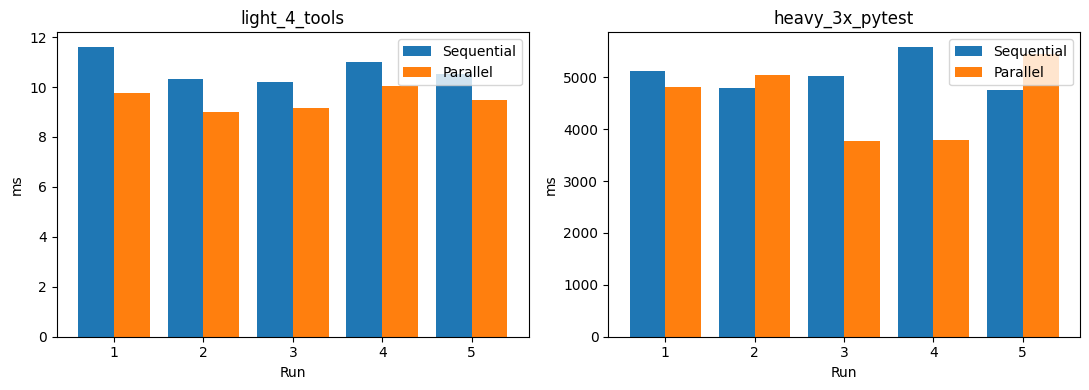

In [21]:
from orchestrator import benchmark
import pandas as pd
import matplotlib.pyplot as plt

bench = await benchmark(runs=5)
display(pd.DataFrame(bench["rows"]))
summary_df = pd.DataFrame(bench["summary"]).T
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, bench["summary"]):
    sub = pd.DataFrame([r for r in bench["rows"] if r["scenario"] == name])
    x = range(len(sub))
    ax.bar([i - 0.2 for i in x], sub["sequential_ms"], 0.4, label="Sequential")
    ax.bar([i + 0.2 for i in x], sub["parallel_ms"], 0.4, label="Parallel")
    ax.set_title(name); ax.set_xlabel("Run"); ax.set_ylabel("ms"); ax.set_xticks(list(x)); ax.set_xticklabels(sub["run"]); ax.legend()
plt.tight_layout(); plt.show()

**Reading the result:** parallelism helps most when work is *slow and independent* (subprocesses, network waits).
For millisecond tools the gain is small because scheduling overhead is comparable to the work itself.

### 17 · Results table, validation and generated artifacts

In [22]:
from orchestrator import build_report, save_report, render_markdown
from observability import load_traces

wf = await run_workflow(REQUEST, mode="dag")
report = build_report(wf, bench)
json_path, md_path = save_report(report)

from IPython.display import Markdown, display
display(Markdown(render_markdown(report)))

vit = next(r["data"] for r in wf["records"] if r["tool"] == "analyze_vitals")
obs = pd.DataFrame([
    ("Tool discovery", "session.list_tools()", ", ".join(wf["tools_discovered"])),
    ("Code/data analysis", "analyze_vitals", f"{vit['total_records']} records, {vit['valid_count']} valid, {vit['invalid_count']} quarantined"),
    ("Triage", "analyze_vitals", str(vit["triage_counts"])),
    ("Automated testing", "run_validation_tests", next(r["data"]["output_tail"].splitlines()[-1] for r in wf["records"] if r["tool"] == "run_validation_tests")),
    ("Path traversal", "read_record_file ../../etc/passwd", "Rejected (security_error)"),
    ("PHI gate", "patient_summary w/o approval", "Blocked by policy"),
], columns=["Test", "Input", "Observed result"])
display(obs)

print("Artifacts:")
for p in [json_path, md_path, *sorted((BASE_DIR / "logs").glob("*"))]:
    print(f"  {p.relative_to(BASE_DIR)}  ({p.stat().st_size} bytes)")
print("\nStored traces:", len(load_traces()))

# Healthcare Records Automation Report

*Synthetic data. Educational use only - not a clinical decision tool.*

- **Generated:** 2026-10-22T07:45:48
- **Trace ID:** TRACE-09C72867  |  **Mode:** dag
- **Request:** Analyze patients.csv vitals, search for fever and run the validation tests.
- **Final status:** **VALIDATED**

## Execution summary

| Planned | Approved | Executed | Succeeded | Failed | Blocked/Skipped | DOP | Layers |
|---|---|---|---|---|---|---|---|
| 3 | 3 | 3 | 3 | 0 | 0 | 2 | 2 |

## Tasks

| Task | Tool | Risk | Status | Time (ms) |
|---|---|---|---|---|
| TASK-001 | search_records | LOW | success | 5.18 |
| TASK-002 | analyze_vitals | MEDIUM | success | 5.46 |
| TASK-003 | run_validation_tests | MEDIUM | success | 1563.78 |

## Clinical alerts

- 3 CRITICAL patient(s) need clinician review: P004, P019, P021
- 3 record(s) failed data-quality checks and were NOT triaged - fix source data.

## Sequential vs parallel

| Scenario | Seq (ms) | Par (ms) | Reduction |
|---|---|---|---|
| light_4_tools | 10.73 | 9.5 | 11.5% |
| heavy_3x_pytest | 5058.03 | 4570.07 | 9.65% |


,Test,Input,Observed result
0,Tool discovery,session.list_tools(),"list_records, read_record_file, search_records..."
1,Code/data analysis,analyze_vitals,"30 records, 27 valid, 3 quarantined"
2,Triage,analyze_vitals,"{'CRITICAL': 3, 'URGENT': 3, 'MONITOR': 3, 'RO..."
3,Automated testing,run_validation_tests,25 passed in 0.03s
4,Path traversal,read_record_file ../../etc/passwd,Rejected (security_error)
5,PHI gate,patient_summary w/o approval,Blocked by policy


Artifacts:
  reports/report_TRACE-09C72867.json  (4294 bytes)
  reports/report_TRACE-09C72867.md  (1100 bytes)
  logs/execution.log  (767 bytes)
  logs/mcp_traces.jsonl  (4702 bytes)
  logs/server.log  (15984 bytes)
  logs/server_stderr.log  (0 bytes)

Stored traces: 5


### 18 · Metrics for your lab report
`DOP` = number of tasks that can run concurrently; `DOS` here = number of sequential layers the dependency graph forces.

In [23]:
s = report["summary"]
print(f"DOP (max parallel tasks)      : {s['DOP']}")
print(f"DOS (sequential layers)       : {s['DOS_layers']}")
print(f"Tasks executed / succeeded    : {s['executed']} / {s['succeeded']}")
print(f"Average tool time             : {s['avg_tool_time_ms']} ms")
print(f"One-time connect cost         : {s['connect_ms']} ms")
for name, v in bench["summary"].items():
    print(f"{name:18}: seq {v['avg_sequential_ms']} ms | par {v['avg_parallel_ms']} ms | reduction {v['time_reduction_percent']}%")

DOP (max parallel tasks)      : 2
DOS (sequential layers)       : 2
Tasks executed / succeeded    : 3 / 3
Average tool time             : 524.81 ms
One-time connect cost         : 2177.6 ms
light_4_tools     : seq 10.73 ms | par 9.5 ms | reduction 11.5%
heavy_3x_pytest   : seq 5058.03 ms | par 4570.07 ms | reduction 9.65%


# Streamlit app
`app.py` puts a dashboard on top of the same orchestrator: run requests, toggle clinician approval, view the triage dashboard,
run the benchmark and inspect traces.

In [24]:
%%writefile app.py
"""Streamlit dashboard - Healthcare Records Automation via MCP.  Run:  streamlit run app.py"""
import asyncio
import json

import pandas as pd
import streamlit as st

from observability import load_traces
from orchestrator import benchmark, build_report, render_markdown, run_workflow, save_report
from policy import TOOL_POLICIES

st.set_page_config(page_title="Healthcare MCP Automation", page_icon="🏥", layout="wide")

TRIAGE_COLORS = {"CRITICAL": "#f8d7da", "URGENT": "#ffe5b4", "MONITOR": "#fff8c4", "ROUTINE": "#d9f2e3"}
EXAMPLES = {
    "Screen + test": "Analyze patients.csv vitals and run the validation tests.",
    "Search": "Search for fever and list all files.",
    "Patient (PHI)": "Give me a summary of patient P021 and analyze vitals.",
    "Read file": "Read patients.csv",
}


def run(coro):
    return asyncio.run(coro)


# ------------------------------------------------------------------ sidebar
st.sidebar.title("🏥 Controls")
mode = st.sidebar.radio("Execution mode", ["dag", "sequential"],
                        help="dag = independent tasks run in parallel; sequential = one by one")
retries = st.sidebar.slider("Max retries (transient failures)", 0, 3, 2)
approve_phi = st.sidebar.checkbox("✅ Clinician approval for patient-level (PHI) tools", value=False)
st.sidebar.caption("Unchecked → `patient_summary` is blocked by the policy layer.")
st.sidebar.divider()
st.sidebar.markdown("**Tool risk policy**")
st.sidebar.dataframe(pd.DataFrame(TOOL_POLICIES).T[["risk", "phi", "approval_required"]],
                     width="stretch")
st.sidebar.warning("Synthetic data · educational use only · not a clinical decision tool")

st.title("Healthcare Records Automation — MCP")
tab_run, tab_dash, tab_bench, tab_trace = st.tabs(
    ["🚀 Run request", "📊 Vitals dashboard", "⏱️ Benchmark", "🔎 Traces"])

# ------------------------------------------------------------------ run tab
with tab_run:
    cols = st.columns(len(EXAMPLES))
    for col, (label, text) in zip(cols, EXAMPLES.items()):
        if col.button(label, width="stretch"):
            st.session_state["request"] = text
    request = st.text_area("Request", key="request", height=80,
                           value=st.session_state.get("request", EXAMPLES["Screen + test"]))

    if st.button("Run workflow", type="primary"):
        approvals = {"patient_summary"} if approve_phi else set()
        with st.spinner("Planning → discovering MCP tools → executing…"):
            st.session_state["wf"] = run(run_workflow(request, approvals, mode, retries))

    wf = st.session_state.get("wf")
    if wf:
        status = wf["validation"]["final_status"]
        (st.success if status == "VALIDATED" else st.warning)(f"Final status: **{status}** · Trace `{wf['trace_id']}`")
        for alert in wf["validation"]["clinical_alerts"]:
            st.error(f"⚠️ {alert}")

        m = st.columns(5)
        m[0].metric("Tasks planned", len(wf["plan"]))
        m[1].metric("Connect (ms)", wf["timing"]["connect_ms"])
        m[2].metric("Execution (ms)", wf["timing"]["execution_ms"])
        m[3].metric("DOP", wf["parallelism"]["DOP"])
        m[4].metric("Layers (DOS)", wf["parallelism"]["DOS_layers"])

        st.subheader("Task results")
        st.dataframe(pd.DataFrame([{k: r[k] for k in ("task_id", "tool", "risk", "status", "attempts",
                                                       "execution_time_ms", "message")} for r in wf["records"]]),
                     width="stretch", hide_index=True)
        if wf["supervisor"]["rejected"]:
            st.warning("Rejected by supervisor")
            st.dataframe(pd.DataFrame(wf["supervisor"]["rejected"]), hide_index=True)

        for rec in wf["records"]:
            with st.expander(f"{rec['task_id']} · {rec['tool']} · {rec['status']}"):
                if rec["data"]:
                    st.json(rec["data"], expanded=False)
                else:
                    st.write(rec["message"] or "No data.")

        st.subheader("Validation")
        st.dataframe(pd.DataFrame(wf["validation"]["validated_tasks"]), width="stretch", hide_index=True)

        report = build_report(wf)
        save_report(report)
        st.download_button("⬇️ Download report (Markdown)", render_markdown(report),
                           file_name=f"{wf['trace_id']}.md")
        st.download_button("⬇️ Download report (JSON)", json.dumps(report, indent=2, default=str),
                           file_name=f"{wf['trace_id']}.json")

# ------------------------------------------------------------------ dashboard
with tab_dash:
    st.caption("Runs the `analyze_vitals` tool through MCP and joins results to the patient table.")
    if st.button("Refresh vitals screening"):
        st.session_state["vitals"] = run(run_workflow("Analyze vitals", mode="dag"))
    vit = st.session_state.get("vitals")
    if vit:
        data = next((r["data"] for r in vit["records"] if r["tool"] == "analyze_vitals"), None)
        if data:
            c = st.columns(5)
            c[0].metric("Total", data["total_records"])
            c[1].metric("Valid", data["valid_count"])
            c[2].metric("Invalid", data["invalid_count"])
            c[3].metric("Critical", data["triage_counts"]["CRITICAL"])
            c[4].metric("Urgent", data["triage_counts"]["URGENT"])
            st.bar_chart(pd.Series(data["triage_counts"]), color="#c0392b")
            df = pd.DataFrame(data["patients"])
            df["findings"] = df["findings"].apply(lambda f: "; ".join(f) or "-")
            st.dataframe(df.style.map(lambda v: f"background-color: {TRIAGE_COLORS.get(v, '')}", subset=["triage"]),
                         width="stretch", hide_index=True)
            if data["invalid_records"]:
                st.subheader("Quarantined records (data-quality failures)")
                st.dataframe(pd.DataFrame([{"patient_id": i["patient_id"], "problems": "; ".join(i["problems"])}
                                           for i in data["invalid_records"]]), hide_index=True,
                             width="stretch")

# ------------------------------------------------------------------ benchmark
with tab_bench:
    runs = st.slider("Runs per scenario", 2, 10, 5)
    if st.button("Run benchmark"):
        with st.spinner("Benchmarking…"):
            st.session_state["bench"] = run(benchmark(runs))
    bench = st.session_state.get("bench")
    if bench:
        st.dataframe(pd.DataFrame(bench["summary"]).T, width="stretch")
        for name in bench["summary"]:
            sub = pd.DataFrame([r for r in bench["rows"] if r["scenario"] == name]).set_index("run")
            st.markdown(f"**{name}**")
            st.bar_chart(sub[["sequential_ms", "parallel_ms"]])
        st.info("Light tools finish in milliseconds, so parallel gains are small. "
                "Subprocess-heavy tools (pytest) show clearer gains.")

# ------------------------------------------------------------------ traces
with tab_trace:
    traces = load_traces()
    st.metric("Stored traces", len(traces))
    if traces:
        st.dataframe(pd.DataFrame([{k: t[k] for k in ("trace_id", "workflow_start", "mode", "total_tasks",
                                                       "failed_tasks", "blocked_tasks", "workflow_status")}
                                   for t in reversed(traces)]), width="stretch", hide_index=True)
        pick = st.selectbox("Inspect trace", [t["trace_id"] for t in reversed(traces)])
        st.json(next(t for t in traces if t["trace_id"] == pick))

Writing app.py


### Launch the app in Colab
Colab can't open `localhost` in your browser, so port 8501 is exposed through a free **Cloudflare quick tunnel** (no account, no password).
1. Run the cell below and wait ~15 seconds.
2. Open the `https://….trycloudflare.com` URL it prints.
3. Stop the cell (■) when finished.

> If the page looks blank or a widget shows an error, **hard-refresh** (Ctrl+Shift+R). Do not use localtunnel (`loca.lt`) — it drops Streamlit's JavaScript files.

In [27]:
import subprocess, os, re, time

subprocess.run("pkill -f 'streamlit run'; pkill -f cloudflared", shell=True)

# 1) start Streamlit
st_log = open(BASE_DIR / "streamlit.log", "w")
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true",
                  "--server.enableCORS", "false", "--server.enableXsrfProtection", "false"],
                 cwd=BASE_DIR, stdout=st_log, stderr=subprocess.STDOUT)
time.sleep(6)

# 2) get cloudflared (single binary)
CF = "/content/cloudflared"
if not os.path.exists(CF):
    subprocess.run(["wget", "-q", "-O", CF,
                    "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64"], check=True)
    os.chmod(CF, 0o755)

# 3) open the tunnel and read the public URL from its log
cf_log = open("/content/cloudflared.log", "w")
subprocess.Popen([CF, "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
                 stdout=cf_log, stderr=subprocess.STDOUT)
for _ in range(40):
    time.sleep(1)
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("/content/cloudflared.log").read())
    if m:
        print("✅ Open your app here:", m.group(0))
        break
else:
    print("Tunnel URL not found. cloudflared log:\n", open("/content/cloudflared.log").read()[-800:])

# keep the cell running so the tunnel stays alive (stop with the ■ button)
while True:
    time.sleep(60)

✅ Open your app here: https://improve-sublime-indoor-once.trycloudflare.com


KeyboardInterrupt: 

## 19 · Download everything
Keep this zip — **Experiment 07** builds on the same agent/tool/validation/trace patterns.

In [26]:
!cd /content && zip -qr Exp06_Healthcare_MCP.zip Exp06_Healthcare_MCP -x "*/__pycache__/*" "*.log"
try:
    from google.colab import files
    files.download("/content/Exp06_Healthcare_MCP.zip")
except ImportError:
    print("Zip created at /content/Exp06_Healthcare_MCP.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
A healthcare records automation system was built on MCP: a FastMCP server exposes six clinic tools; an MCP client discovers and invokes them over stdio;
a planner and supervisor create and validate task graphs; a policy layer enforces risk levels and a **PHI approval gate**; a DAG executor runs independent
tasks in parallel and gates dependent ones; failures are classified and only transient ones retried; a validator separates *software correctness* from
*clinical alerts*; and every run is traced to JSONL. Measured results show parallel execution gives modest gains for millisecond tools and clearer gains
for subprocess-heavy tools. A Streamlit dashboard exposes the whole pipeline.